### Comparison between SteadierCom and experimental results

In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt

import sys

sys.path.append("../functions/")
import general

import compare_met_exp_sim.correlation as correlation
import compare_met_exp_sim.diagnostic as diagnostic
import compare_met_exp_sim.venturelli2018 as venturelli2018
import compare_met_exp_sim.general_funcs as general_funcs

In [2]:
%load_ext autoreload
%autoreload 2

#### Mapping names to seed ids (seem to have a good overlap)

In [3]:
with open("../data/Venturelli2018/generated/metid2metname.json") as file:
    metid2metname = json.load(file)
    
with open("../data/Venturelli2018/generated/metname2metanetx.json") as file:
    metname2metanetx = json.load(file)
    
with open("../data/Venturelli2018/generated/metname_groups.json") as file:
    metname_groups = json.load(file)

with open("../data/Venturelli2018/generated/metname2group.json") as file:
    metname2group = json.load(file)

with open("../data/Venturelli2018/generated/metid2group.json") as file:
    metid2group = json.load(file)

In [4]:
len(set(metname2metanetx.keys())-set(metid2metname.values()))

33

**Metabolomics**

In [5]:
raw_data_exp,signal_exp = venturelli2018.load_experimental_results()

INFO     | load_experimental_results_venturelli loads and processes metabolomics data from Venturelli et al. 2018 (Dataset EV4) in
	 ../data/Venturelli2018/msb178157-sup-0005-datasetev4.xlsx

	 Results are filtered by metabolites present in models.
INFO     | _assign_groups_and_filter_by_models assigns metabolite groups to the metabolites 
 and filters out metabolites that do not exist in any model.
INFO     | Loading models from Venturelli et al (2018)...


**Load steadiercom results**

In [6]:
simulation_dict = venturelli2018.load_simulation_results(metid2group)

INFO     | load_simulation_results loads simulation results from 
	../output/Venturelli2018/results_steadiercom, 
	../output/Venturelli2018/steadycom and 
	../output/Venturelli2018/smetana
 Only loads results for community 'NONE' (full community)
INFO     | _prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
INFO     | _prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
INFO     | _prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
INFO     | _prepare_sim_met_venturelli removes environment from donors and all compounds that are not found in metabolomics and map to AGORA identifiers
INFO     | _prepare_sim_met_venturelli removes environment from donors and all compounds that are not found in metabolomics and map 

## Correlation analysis - continuous data 


**Motivation**: Seeing if there is a correlation between simulated and experimental results.

**Experimental data**: Relative concentration change of compound in log2. According to Venturelli et al. (2018), log2(C_diff) between -1 and 1 is non-significant. 

**Simulated data**: From three different simulation methods: steadiercom, steadycom and smetana and different configurations of these. The metric used for meassure the strength of a met-member interaction depends on the simulation method. For example for steadiercom there are three options: frequency, rate, mass_rate. 
- Processing: 
    - Removes compounds that were not in the Venturelli et al. study from simulation results.
    - Adjusts metabolite and member names for merging with experimental data. 

**Expected results:**
*NOTE: Consumption in the experimental data is negative while production is positive, but in the simulated data consumption/production are both positive. Because of this:*
- We expect a **negative trend** for receiving rate/frequency with change in concentration. 
- We expect a **positive trend** for donating rate/frequency with change in concentration.  

**Methods:**
- Correlation: Kendall's Tau - A non-parametric and rank-based method - better at handling ties between values on either x-axis or y-axis compared to Spearman. Since the metrics frequency and MUS give a maximum value of 1 we end up with many ties in our datasets.

INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


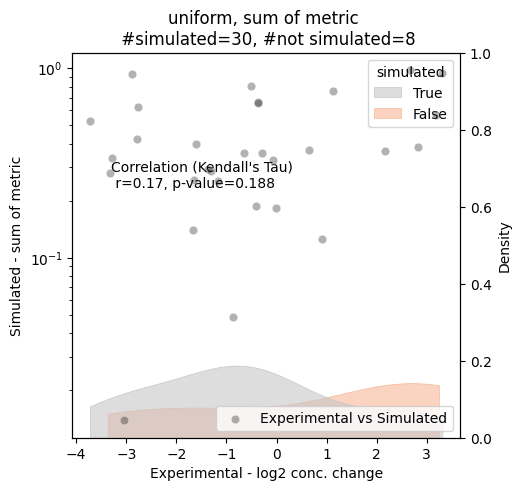

In [7]:
signal_exp_example_dict = {(f"member_{np.random.randint(0,10)}",f"met_{np.random.randint(0,10)}"):np.random.uniform(-4,4) for _ in range(50)}
signal_exp_example = pd.Series(signal_exp_example_dict)
signal_exp_example.index.names = ["member","met_group"]
signal_exp_example.name = "experimental"

n_size = 30
membs_mets = np.random.choice(signal_exp_example.index,replace=False,size=n_size)
members=[member for member,_ in membs_mets]
mets=[met for _,met in membs_mets]
simulation_values_uniform = [np.random.uniform(0,1) for _ in range(n_size)]

simulation_res_uniform = pd.DataFrame({"receiver":members,
              "met_group":mets,
              "metric":simulation_values_uniform})


func = lambda x: (x**2)/10
simulation_values_corr = [func(value) for _,value in signal_exp_example.items() if value<0]
simulation_res_corr = pd.DataFrame({"receiver":[member for (member,_),value in signal_exp_example.items() if value<0],
              "met_group":[met for (_,met),value in signal_exp_example.items() if value<0],
              "metric":simulation_values_corr})

simulation_dict_example = {"receiver":{"simulation_method":{"uniform":simulation_res_uniform,
                                                            "correlated":simulation_res_corr}}}

fig,ax,ax_twin=correlation.make_scatterplot(simulation_dict_example, 
                             signal_exp_example,
                             name="uniform",
                             simulation_method="simulation_method",
                             receiver_or_donor="receiver",
                             metric="metric",
                             agg_method="sum",
                            met_column="met_group",
                            ax=None,
                            verbose=True,
                            legend=True)


INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


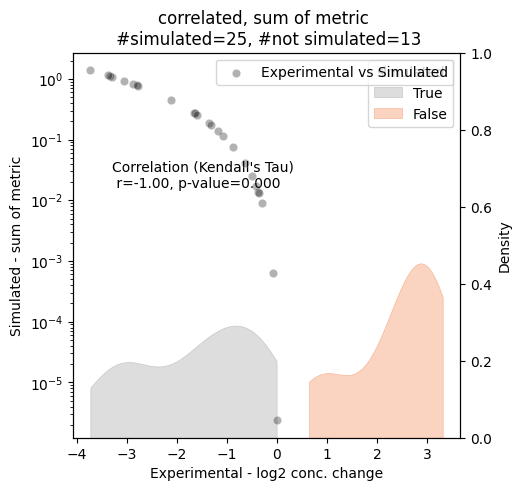

In [8]:

fig,ax,ax_twin=correlation.make_scatterplot(simulation_dict_example, 
                             signal_exp_example,
                             name="correlated",
                             simulation_method="simulation_method",
                             receiver_or_donor="receiver",
                             metric="metric",
                             agg_method="sum",
                            met_column="met_group",
                            ax=None,
                            verbose=True,
                            legend=True)


### Best predictors of receiver-met relationship

In [9]:
results_corr_df = venturelli2018.find_correlations(simulation_dict,signal_exp)

In [10]:

receiver_or_donor = "receiver"
best_donor_predictor = results_corr_df.xs(receiver_or_donor,level=0).sort_values('r')
best_donor_predictor

r  \
simulation_method condition                              agg_method metric                
steadycom         SteadyCom - Nothing fixed              sum        rate?     -0.151821   
steadiercom       SteadierCom - fixed growth             sum        frequency -0.135178   
                  SteadierCom - fixed growth & abundance sum        frequency -0.135108   
steadycom         SteadyCom - Fixed  abundance           sum        rate?     -0.123331   
steadiercom       SteadierCom - fixed abundance          sum        frequency -0.101581   
                                                                    rate      -0.075466   
                  SteadierCom - fixed growth & abundance sum        rate      -0.071674   
                  SteadierCom - fixed growth             sum        rate      -0.061433   
smetana           Smetana                                sum        mus        0.333333   

                                                                                p-value  
simulation_method condition                              agg_method metric               
steadycom         SteadyCom - Nothing fixed              sum        rate?      0.011031  
steadiercom       SteadierCom - fixed growth             sum        frequency  0.008727  
                  SteadierCom - fixed growth & abundance sum        frequency  0.013217  
steadycom         SteadyCom - Fixed  abundance           sum        rate?      0.034528  
steadiercom       SteadierCom - fixed abundance          sum        frequency  0.066319  
                                                                    rate       0.155353  
                  SteadierCom - fixed growth & abundance sum        rate       0.173112  
                  SteadierCom - fixed growth             sum        rate       0.230182  
smetana           Smetana                                sum        mus        0.381349

INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


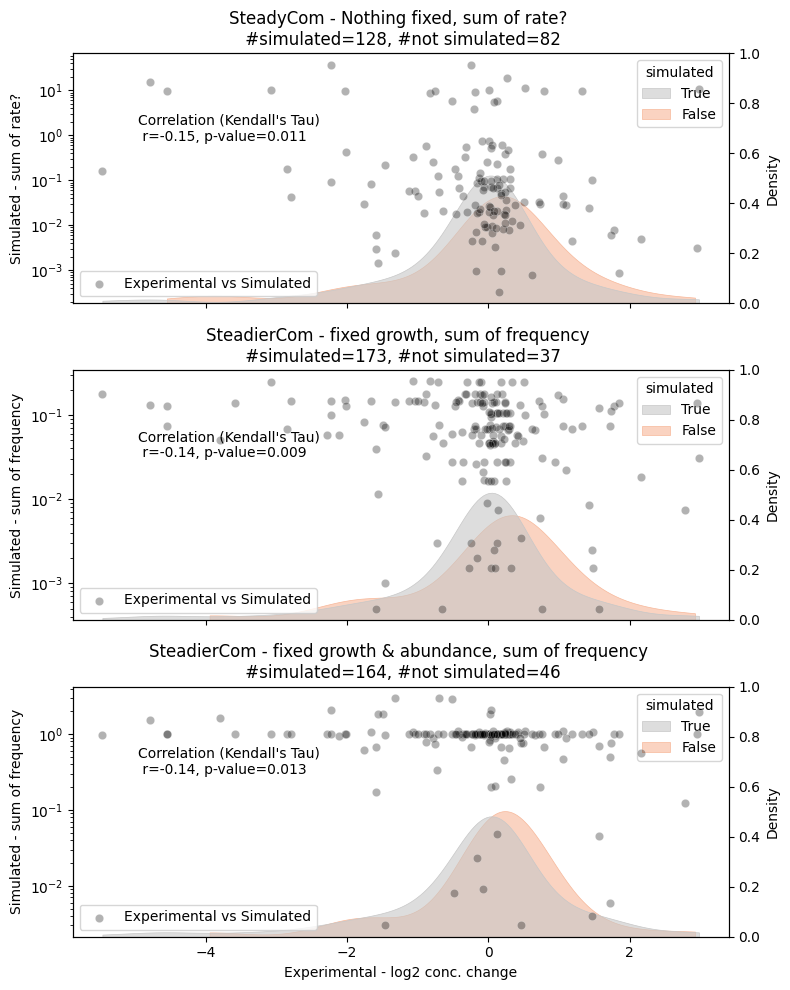

In [11]:
top3 = best_donor_predictor.head(3).index

fig, axs = plt.subplots(3,1,figsize=(8,10))

i = 0

for  index in top3:
    dict_ = dict(zip(top3.names,index))

    ax = axs[i]
    fig,ax,ax_twin = correlation.make_scatterplot(simulation_dict,    
                                                        signal_exp,
                                                        name=dict_["condition"],
                                                        simulation_method=dict_["simulation_method"],
                                                        receiver_or_donor=receiver_or_donor,
                                                        agg_method=dict_["agg_method"],
                                                        metric=dict_["metric"],
                                                        ax=ax)
    if i<2:
        ax.set_xlabel("")
        ax.set_xticklabels([])
    i+=1

fig.tight_layout()


### Best predictors of donor-met relationship

In [12]:

receiver_or_donor = "donor"
best_donor_predictor = results_corr_df.xs(receiver_or_donor,level=0).sort_values('r',ascending=False)
best_donor_predictor



r  \
simulation_method condition                              agg_method metric                
steadycom         SteadyCom - Nothing fixed              sum        rate?      0.284211   
steadiercom       SteadierCom - fixed growth             sum        rate       0.169082   
                                                                    frequency  0.016619   
steadycom         SteadyCom - Fixed  abundance           sum        rate?      0.000000   
steadiercom       SteadierCom - fixed abundance          sum        frequency -0.011671   
                  SteadierCom - fixed growth & abundance sum        rate      -0.012066   
                                                                    frequency -0.014367   
                  SteadierCom - fixed abundance          sum        rate      -0.093023   
smetana           Smetana                                sum        mus       -0.233550   

                                                                                p-value  
simulation_method condition                              agg_method metric               
steadycom         SteadyCom - Nothing fixed              sum        rate?      0.085502  
steadiercom       SteadierCom - fixed growth             sum        rate       0.097534  
                                                                    frequency  0.871921  
steadycom         SteadyCom - Fixed  abundance           sum        rate?      1.000000  
steadiercom       SteadierCom - fixed abundance          sum        frequency  0.911378  
                  SteadierCom - fixed growth & abundance sum        rate       0.899528  
                                                                    frequency  0.880791  
                  SteadierCom - fixed abundance          sum        rate       0.373436  
smetana           Smetana                                sum        mus        0.537453

INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


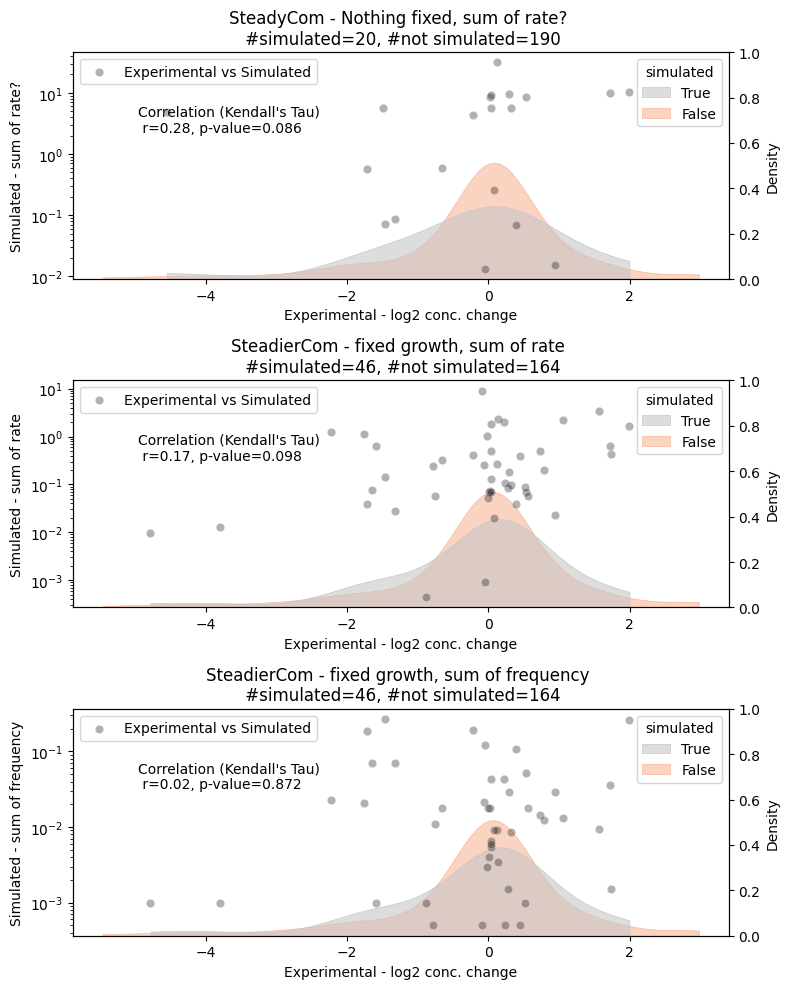

In [13]:
top3 = best_donor_predictor.head(3).index

fig, axs = plt.subplots(3,1,figsize=(8,10))

i = 0

for  index in top3:
    dict_ = dict(zip(top3.names,index))

    ax = axs[i]
    fig,ax,ax_twin = correlation.make_scatterplot(simulation_dict,    
                                                        signal_exp,
                                                        name=dict_["condition"],
                                                        simulation_method=dict_["simulation_method"],
                                                        receiver_or_donor=receiver_or_donor,
                                                        agg_method=dict_["agg_method"],
                                                        metric=dict_["metric"],
                                                        ax=ax)
    i+=1

fig.tight_layout()


###  SteadierCom results - frequency

INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


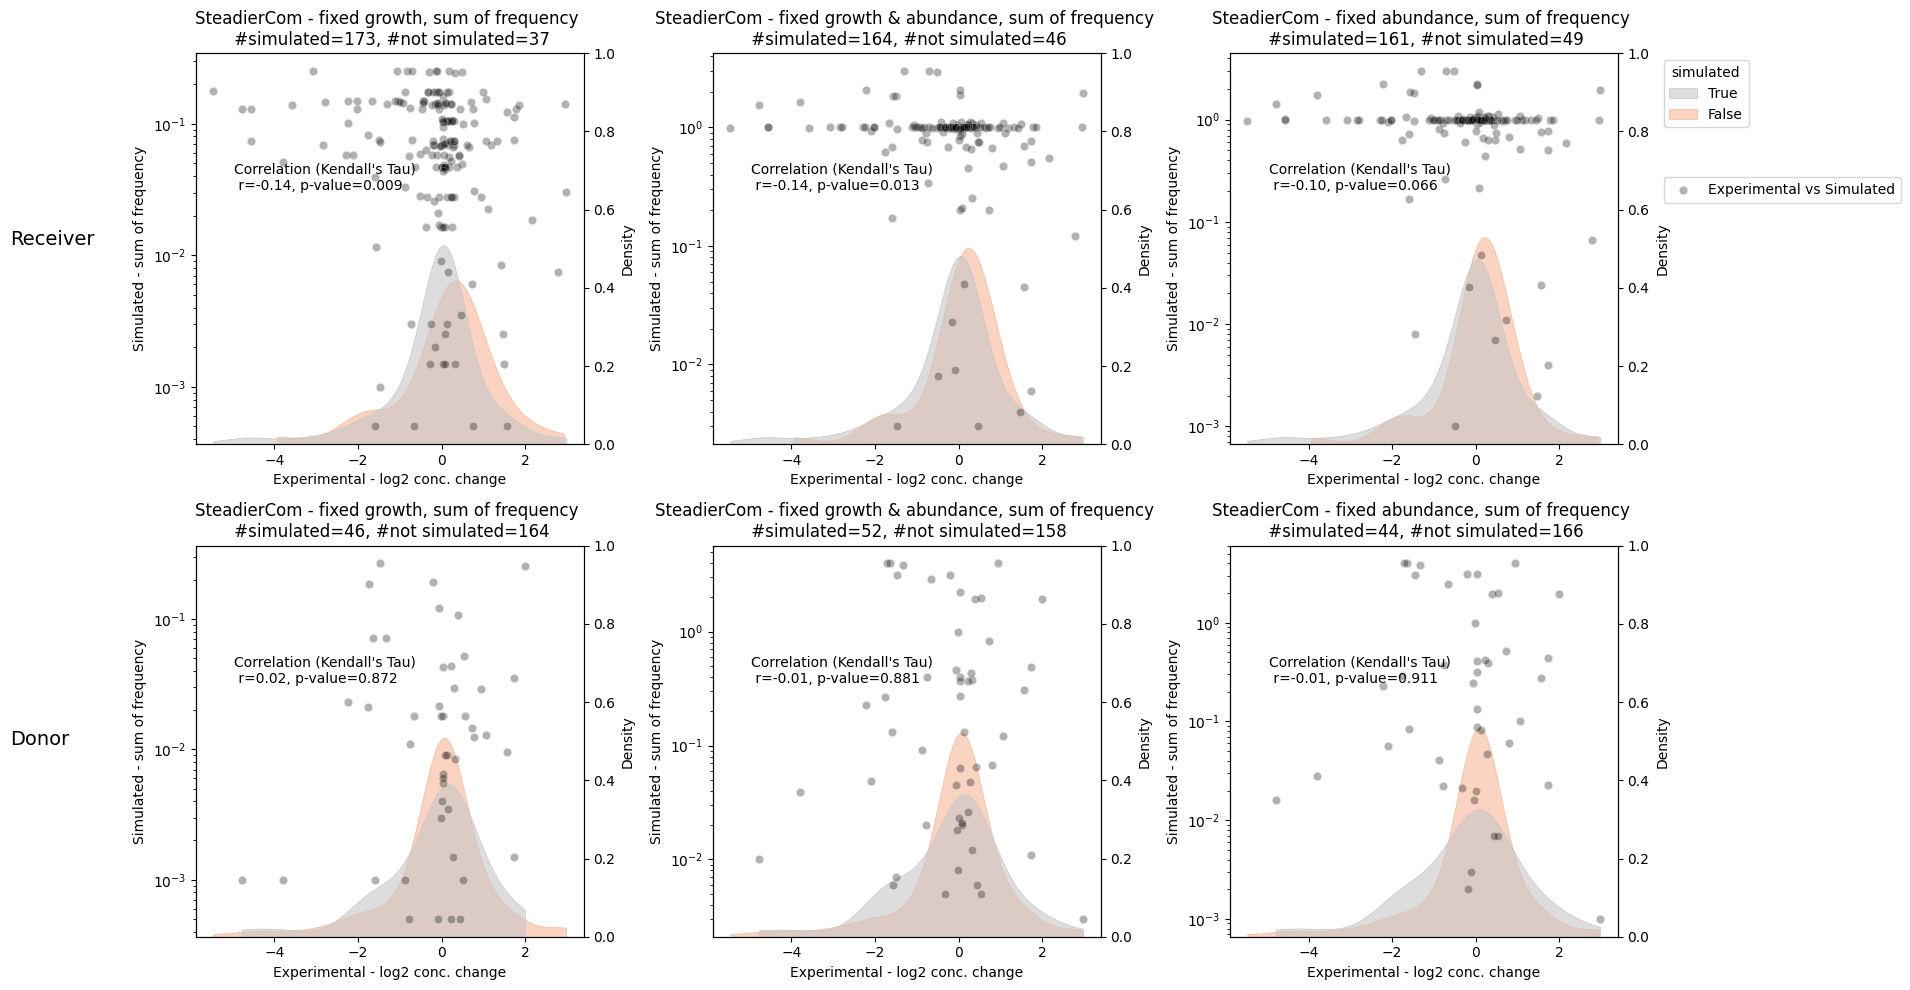

In [14]:
fig, axs, twin_axes = correlation.make_scatterplots_simulation_method(simulation_dict, 
                                                signal_exp,
                                                simulation_method="steadiercom",
                                                metric="frequency",
                                                )

###  SteadierCom results - rate

INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


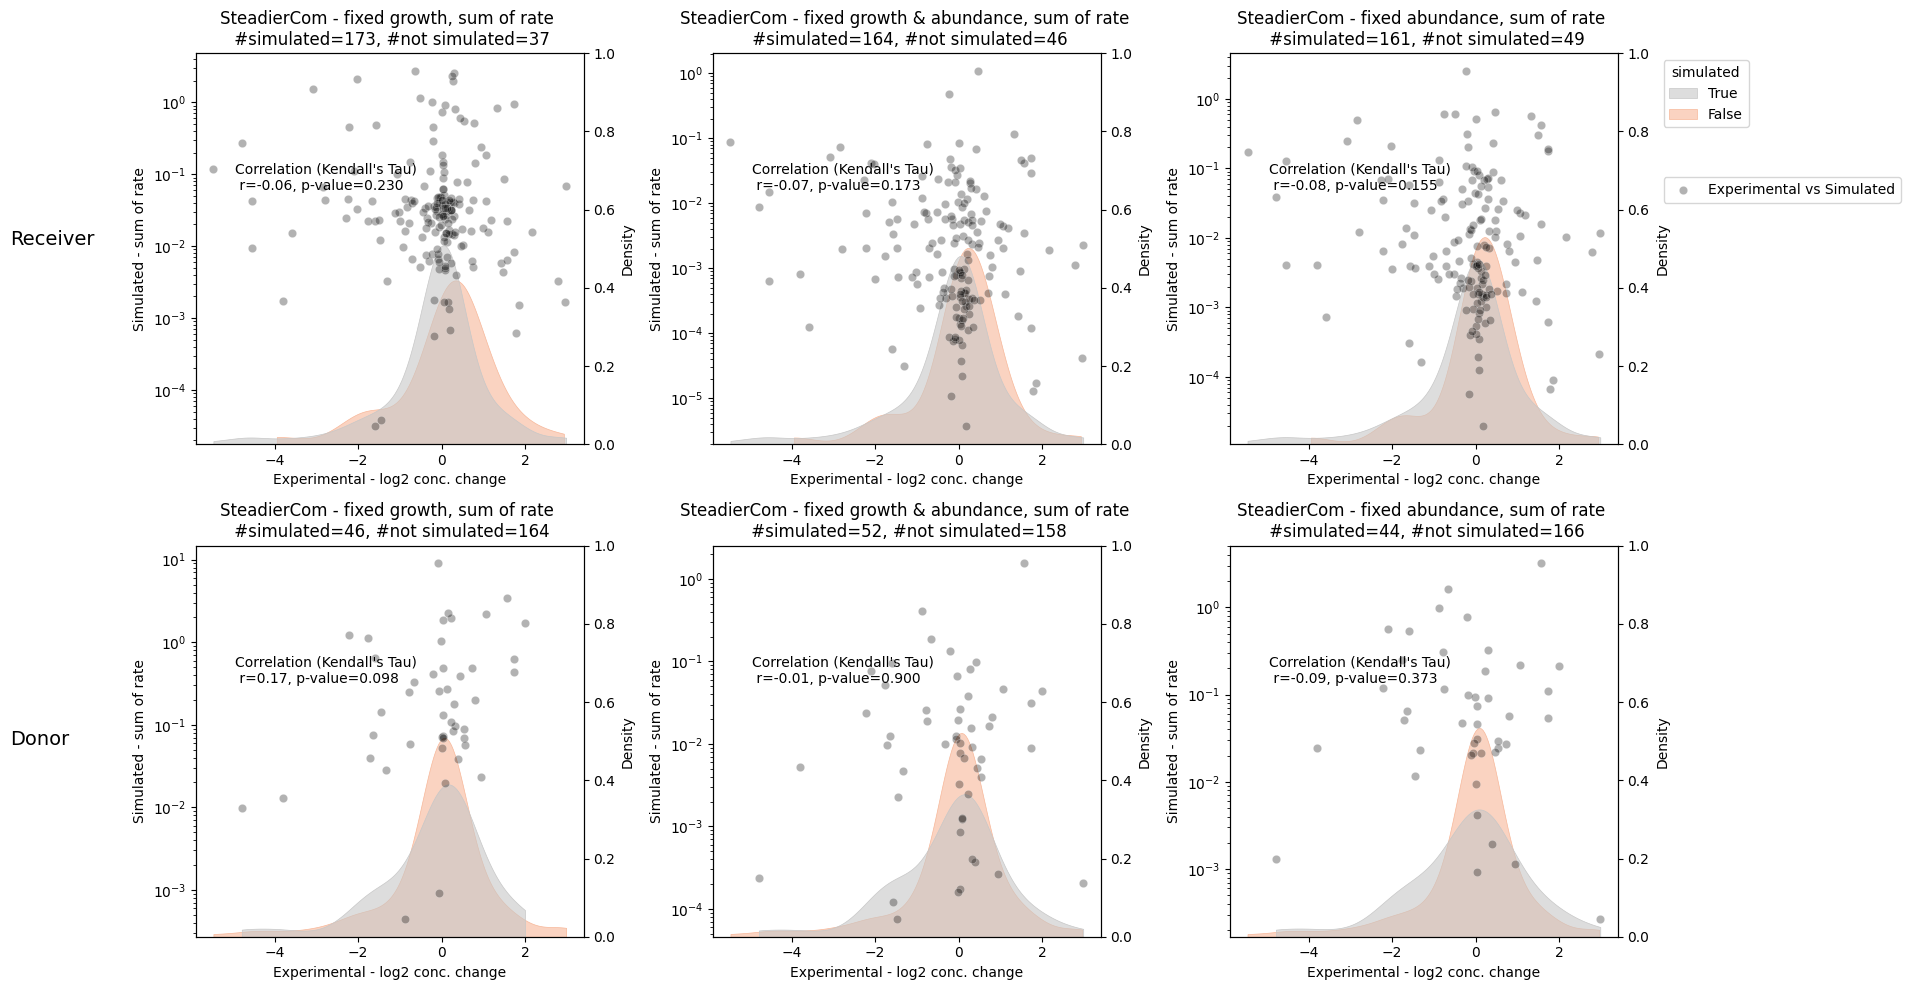

In [15]:
fig, axs, twin_axes = correlation.make_scatterplots_simulation_method(simulation_dict, 
                                                signal_exp,
                                                simulation_method="steadiercom",
                                                metric="rate",
                                                )

###  SteadyCom results - rate?

INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


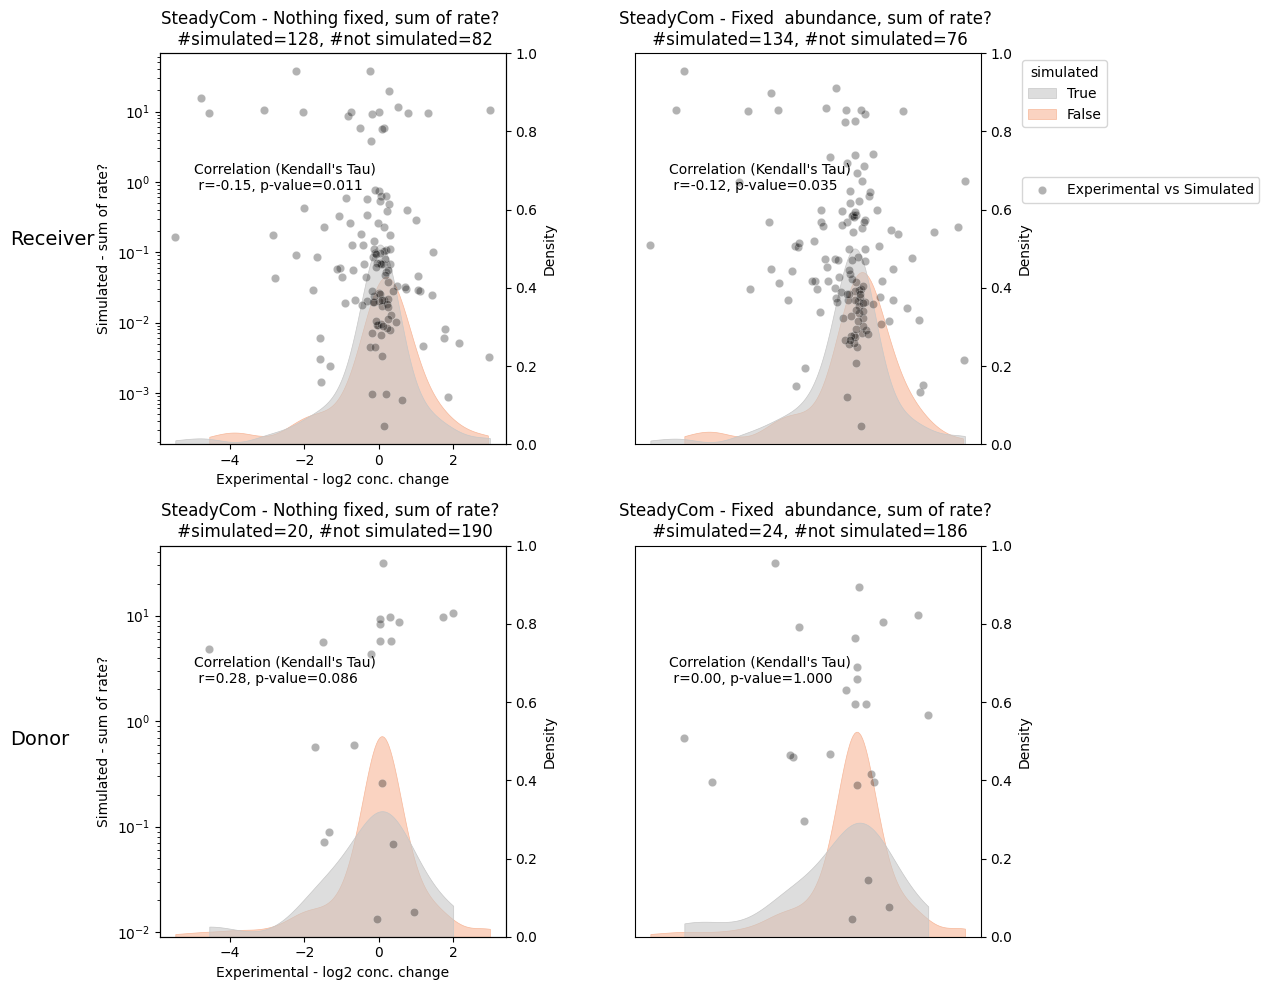

In [16]:
fig, axs, twin_axes = correlation.make_scatterplots_simulation_method(simulation_dict, 
                                                signal_exp,
                                                simulation_method="steadycom",
                                                metric="rate?",
                                                )

axs[-1,-1].set_axis_off()
axs[0,-1].set_axis_off()

###  SMETANA results - MUS

INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
INFO     | make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


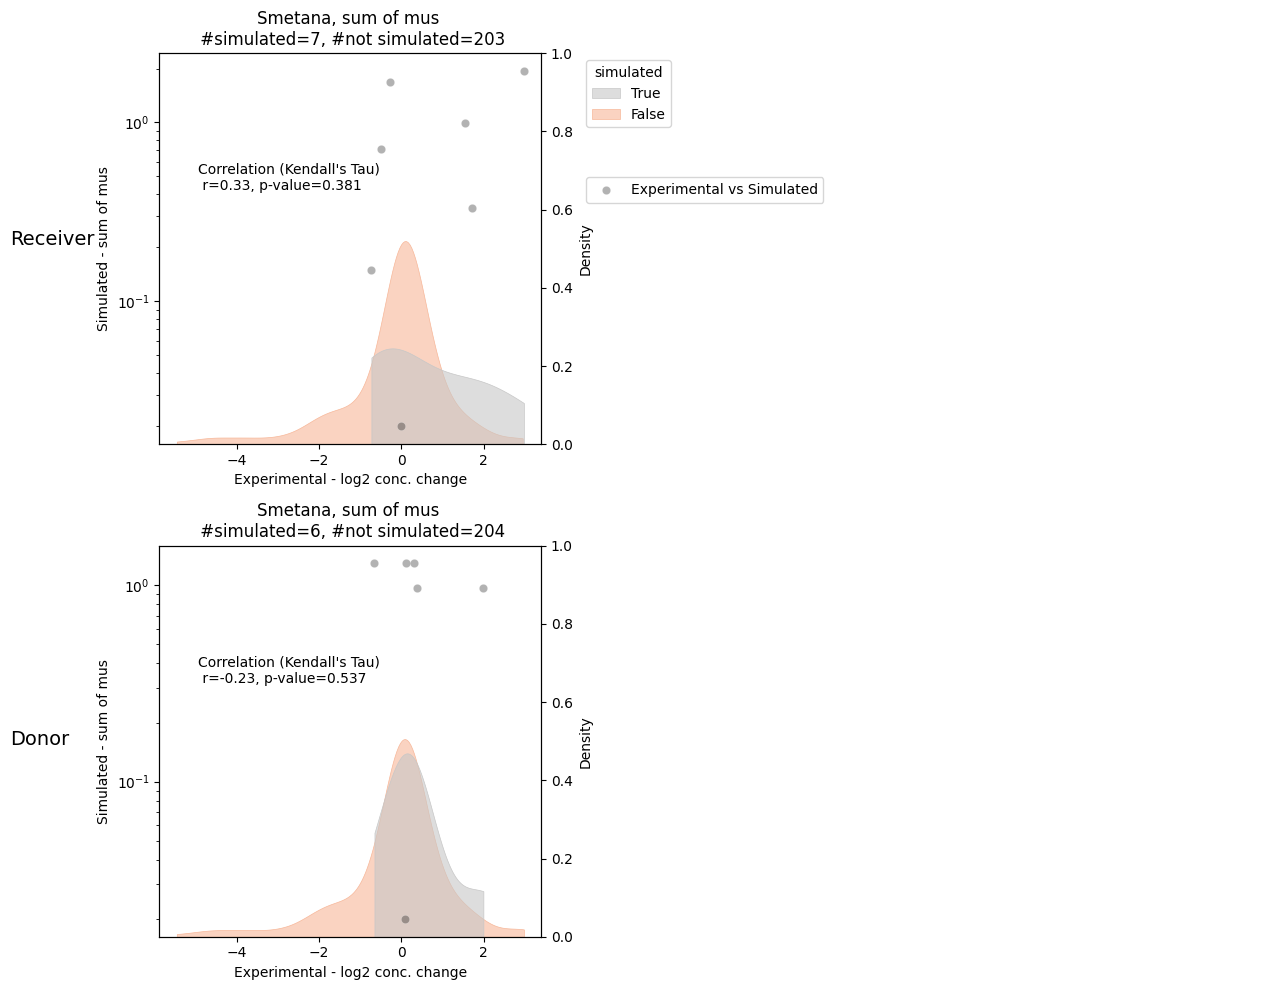

In [17]:
fig, axs, twin_axes = correlation.make_scatterplots_simulation_method(simulation_dict, 
                                                signal_exp,
                                                simulation_method="smetana",
                                                metric="mus",
                                                )

axs[-1,-1].set_axis_off()
axs[0,-1].set_axis_off()

# Diagnostic analysis - Binary data

In [18]:
support_df = diagnostic.identify_support(signal_exp)
support_df.sort_index(ascending=False)

positive_support  negative_support  total  no-skill line
receiver 1.00                34               176    210       0.161905
         0.50                47               163    210       0.223810
         0.25                59               151    210       0.280952
donor    1.00                22               188    210       0.104762
         0.50                42               168    210       0.200000
         0.25                65               145    210       0.309524

In [19]:
len(raw_data_exp.columns)

12

## Precision-Recall curves

In [20]:
results_pr_auc_df = venturelli2018.find_diagnostic_PR_pvalues(simulation_dict,signal_exp)

INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


steadiercom, SteadierCom - fixed growth, receiver, frequency
steadiercom, SteadierCom - fixed growth & abundance, receiver, frequency
steadiercom, SteadierCom - fixed abundance, receiver, frequency


INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


steadiercom, SteadierCom - fixed growth, donor, frequency
steadiercom, SteadierCom - fixed growth & abundance, donor, frequency
steadiercom, SteadierCom - fixed abundance, donor, frequency


INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


...

steadycom, SteadyCom - Nothing fixed, donor, rate?
steadycom, SteadyCom - Fixed  abundance, donor, rate?


INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


smetana, Smetana, receiver, mus


INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


smetana, Smetana, donor, mus


In [21]:
results_pr_auc_df.xs("receiver").sort_values(by="p_value")

p_value
simulation_method condition                              agg_method metric    exp_thresh         
steadiercom       SteadierCom - fixed growth & abundance sum        frequency 0.5          0.0004
                  SteadierCom - fixed abundance          sum        frequency 0.5          0.0005
                  SteadierCom - fixed growth & abundance sum        frequency 1.0          0.0022
                  SteadierCom - fixed growth             sum        frequency 0.5          0.0033
steadycom         SteadyCom - Fixed  abundance           sum        rate?     0.5          0.0055
steadiercom       SteadierCom - fixed abundance          sum        frequency 1.0          0.0090
steadycom         SteadyCom - Nothing fixed              sum        rate?     0.5          0.0197
                  SteadyCom - Fixed  abundance           sum        rate?     1.0          0.0220
steadiercom       SteadierCom - fixed growth & abundance sum        rate      0.5          0.0439
                  SteadierCom - fixed growth             sum        rate      0.5          0.0481
steadycom         SteadyCom - Nothing fixed              sum        rate?     1.0          0.0485
steadiercom       SteadierCom - fixed growth             sum        frequency 1.0          0.0506
                  SteadierCom - fixed abundance          sum        rate      0.5          0.0716
                  SteadierCom - fixed growth & abundance sum        rate      1.0          0.1428
                  SteadierCom - fixed abundance          sum        rate      1.0          0.1969
                  SteadierCom - fixed growth             sum        rate      1.0          0.3136
smetana           Smetana                                sum        mus       1.0          0.9409
                                                                              0.5          0.9522

In [22]:
results_pr_auc_df.xs("donor").sort_values(by="p_value")

p_value
simulation_method condition                              agg_method metric    exp_thresh         
steadiercom       SteadierCom - fixed growth             sum        rate      1.0          0.0449
                  SteadierCom - fixed abundance          sum        rate      1.0          0.0590
                  SteadierCom - fixed growth & abundance sum        rate      1.0          0.0720
steadycom         SteadyCom - Nothing fixed              sum        rate?     1.0          0.1146
steadiercom       SteadierCom - fixed growth             sum        rate      0.5          0.1424
                  SteadierCom - fixed abundance          sum        rate      0.5          0.1988
steadycom         SteadyCom - Nothing fixed              sum        rate?     0.5          0.2037
steadiercom       SteadierCom - fixed growth & abundance sum        rate      0.5          0.2490
                  SteadierCom - fixed growth             sum        frequency 0.5          0.2576
                  SteadierCom - fixed abundance          sum        frequency 0.5          0.2625
                  SteadierCom - fixed growth             sum        frequency 1.0          0.2690
                  SteadierCom - fixed growth & abundance sum        frequency 0.5          0.3440
steadycom         SteadyCom - Fixed  abundance           sum        rate?     1.0          0.3627
                                                                              0.5          0.4164
smetana           Smetana                                sum        mus       1.0          0.4258
steadiercom       SteadierCom - fixed abundance          sum        frequency 1.0          0.4927
                  SteadierCom - fixed growth & abundance sum        frequency 1.0          0.5791
smetana           Smetana                                sum        mus       0.5          0.9335

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_met_exp_sim/diagnostic.py:382: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


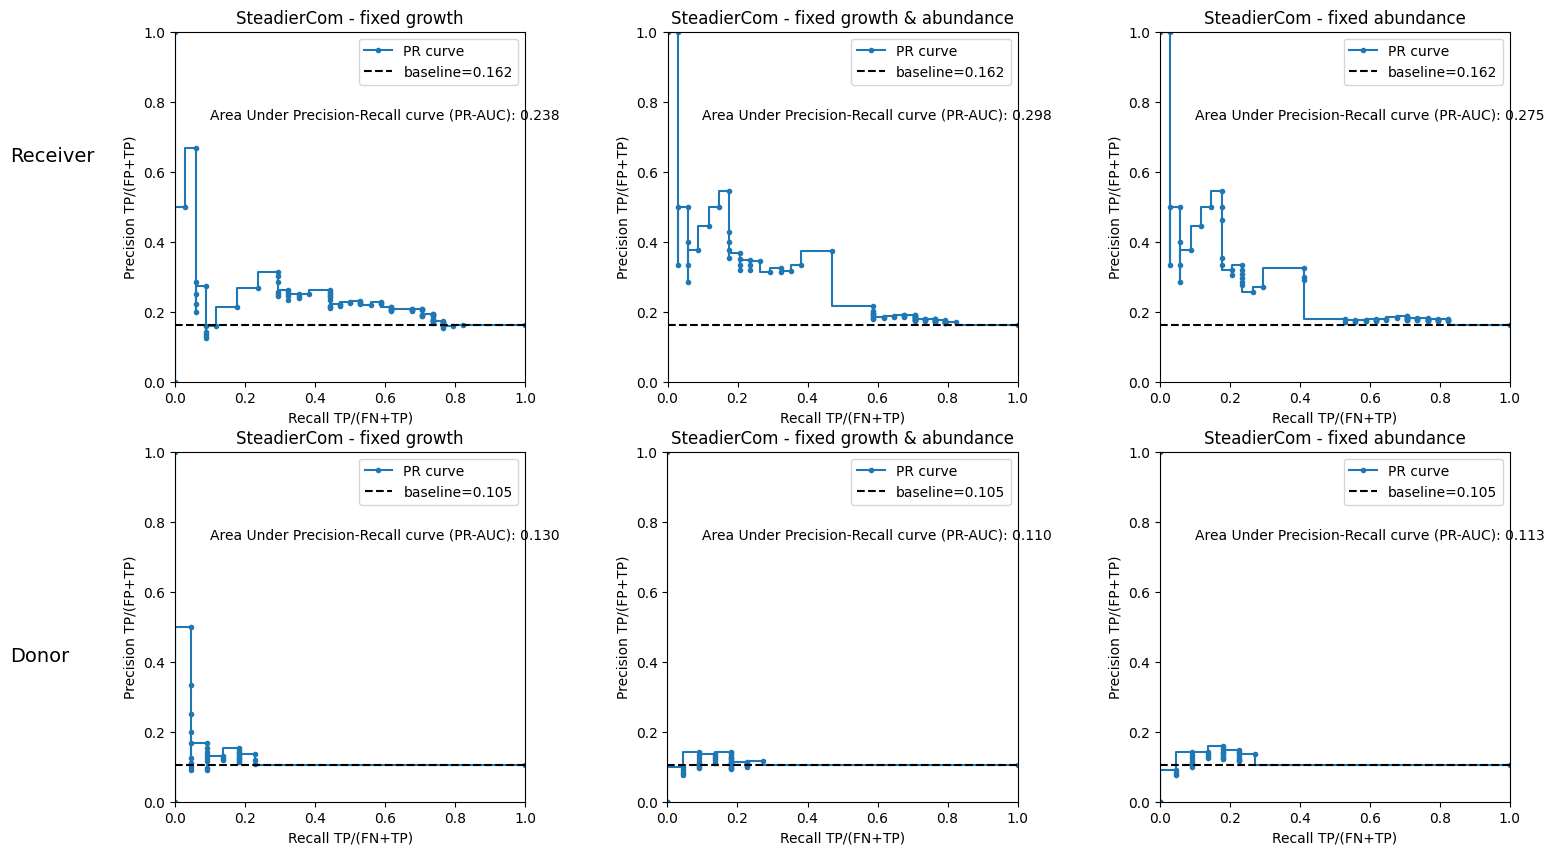

In [23]:
fig,axs = diagnostic.plot_diagnostic_curves(simulation_dict,
                                                    signal_exp,
                                                    simulation_method="steadiercom",
                                                    metric="frequency",
                                                    met_column="met_group",
                                                    agg_method="sum")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_met_exp_sim/diagnostic.py:382: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


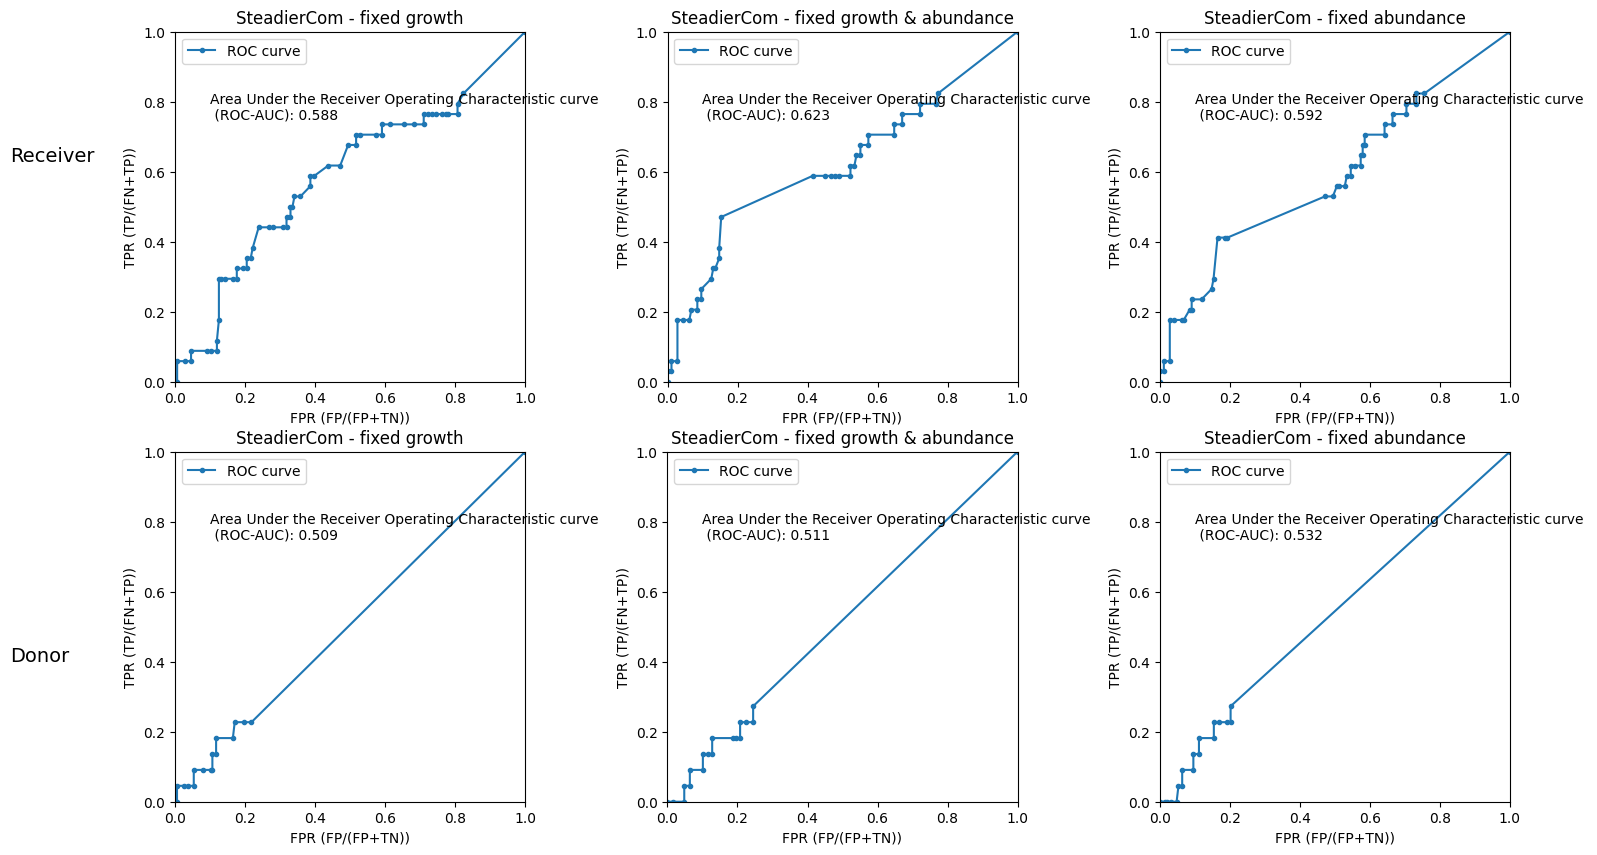

In [24]:
fig,axs = diagnostic.plot_diagnostic_curves(simulation_dict,
                                           signal_exp,
                                           PR_or_ROC="ROC",
                                           simulation_method="steadiercom",
                                           metric="frequency",
                                           met_column="met_group",
                                           agg_method="sum")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_met_exp_sim/diagnostic.py:382: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


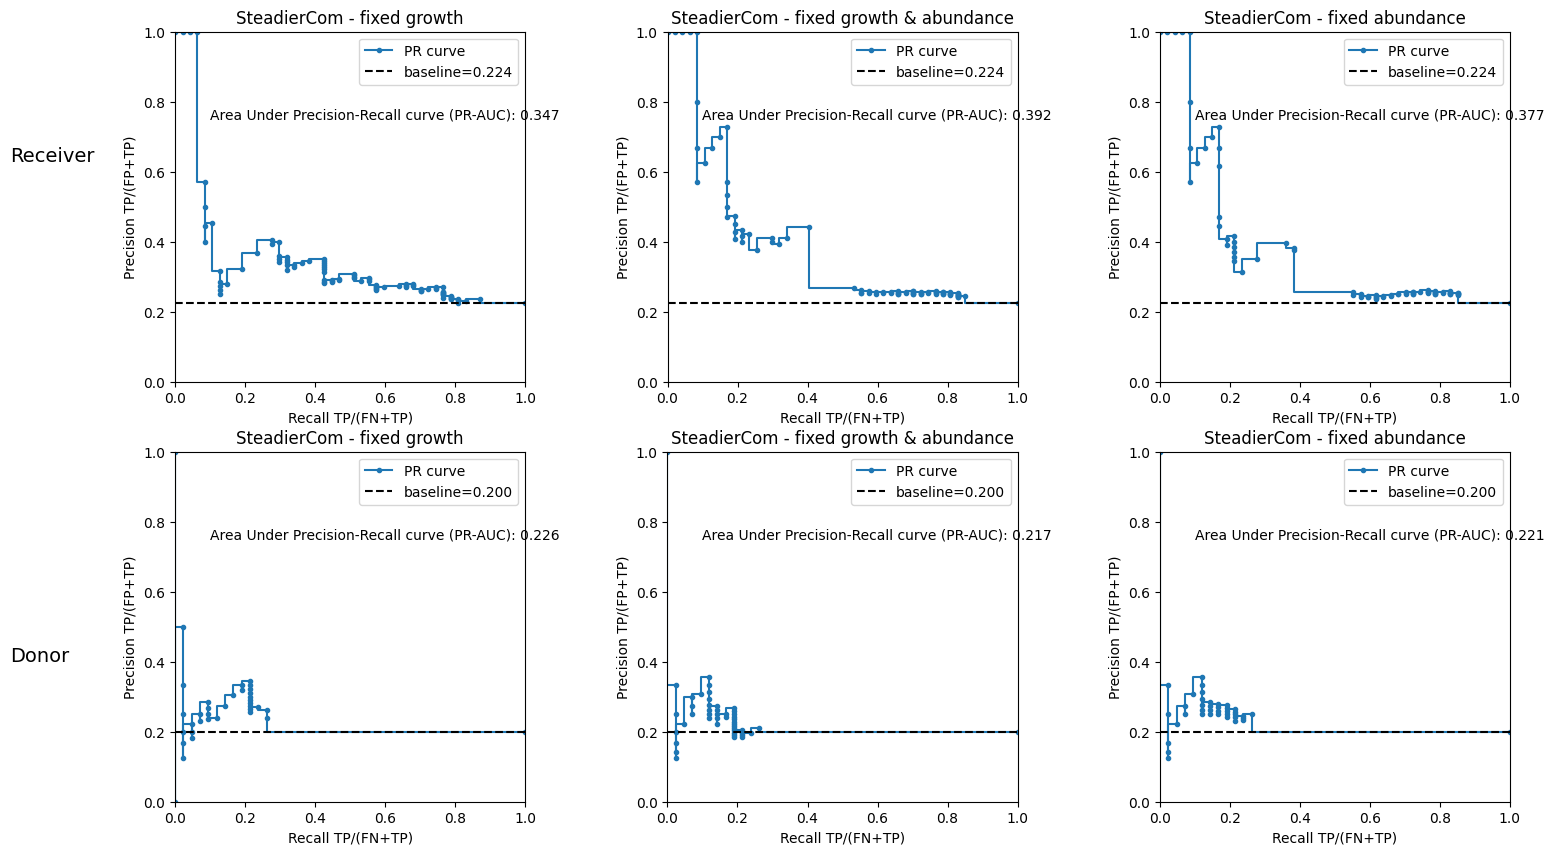

In [25]:
fig,axs = diagnostic.plot_diagnostic_curves(simulation_dict,
                                                    signal_exp,
                                                    exp_thresh=0.5,
                                                    simulation_method="steadiercom",
                                                    metric="frequency",
                                                    met_column="met_group",
                                                    agg_method="sum")


INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_met_exp_sim/diagnostic.py:382: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


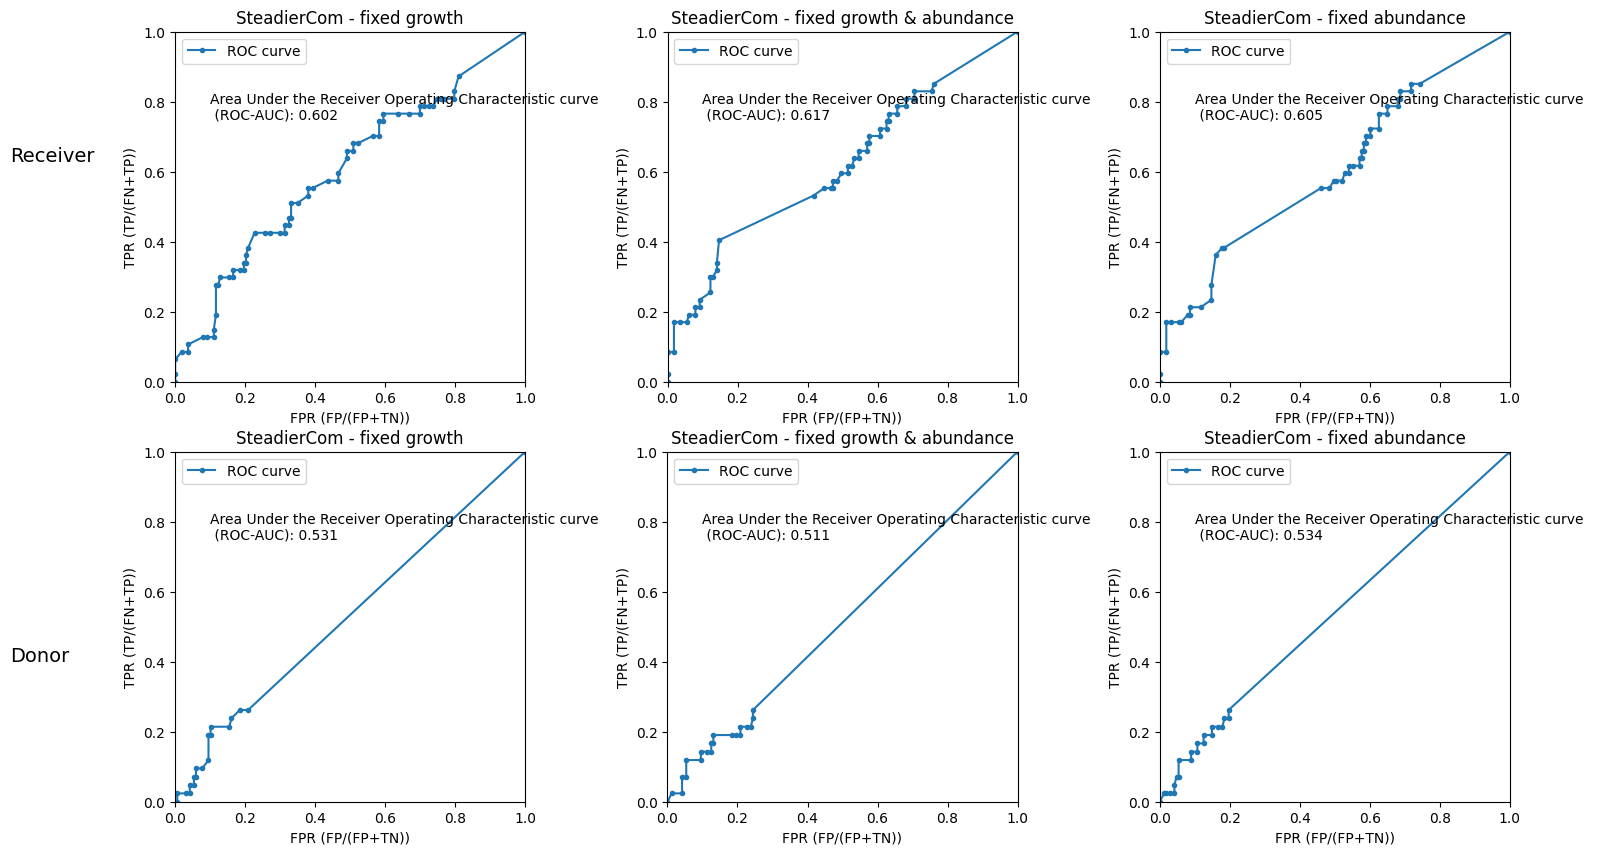

In [26]:
fig,axs = diagnostic.plot_diagnostic_curves(simulation_dict,
                                                    signal_exp,
                                                    exp_thresh=0.5,
                                                    simulation_method="steadiercom",
                                                    PR_or_ROC="ROC",
                                                    metric="frequency",
                                                    met_column="met_group",
                                                    agg_method="sum")


INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_met_exp_sim/diagnostic.py:382: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


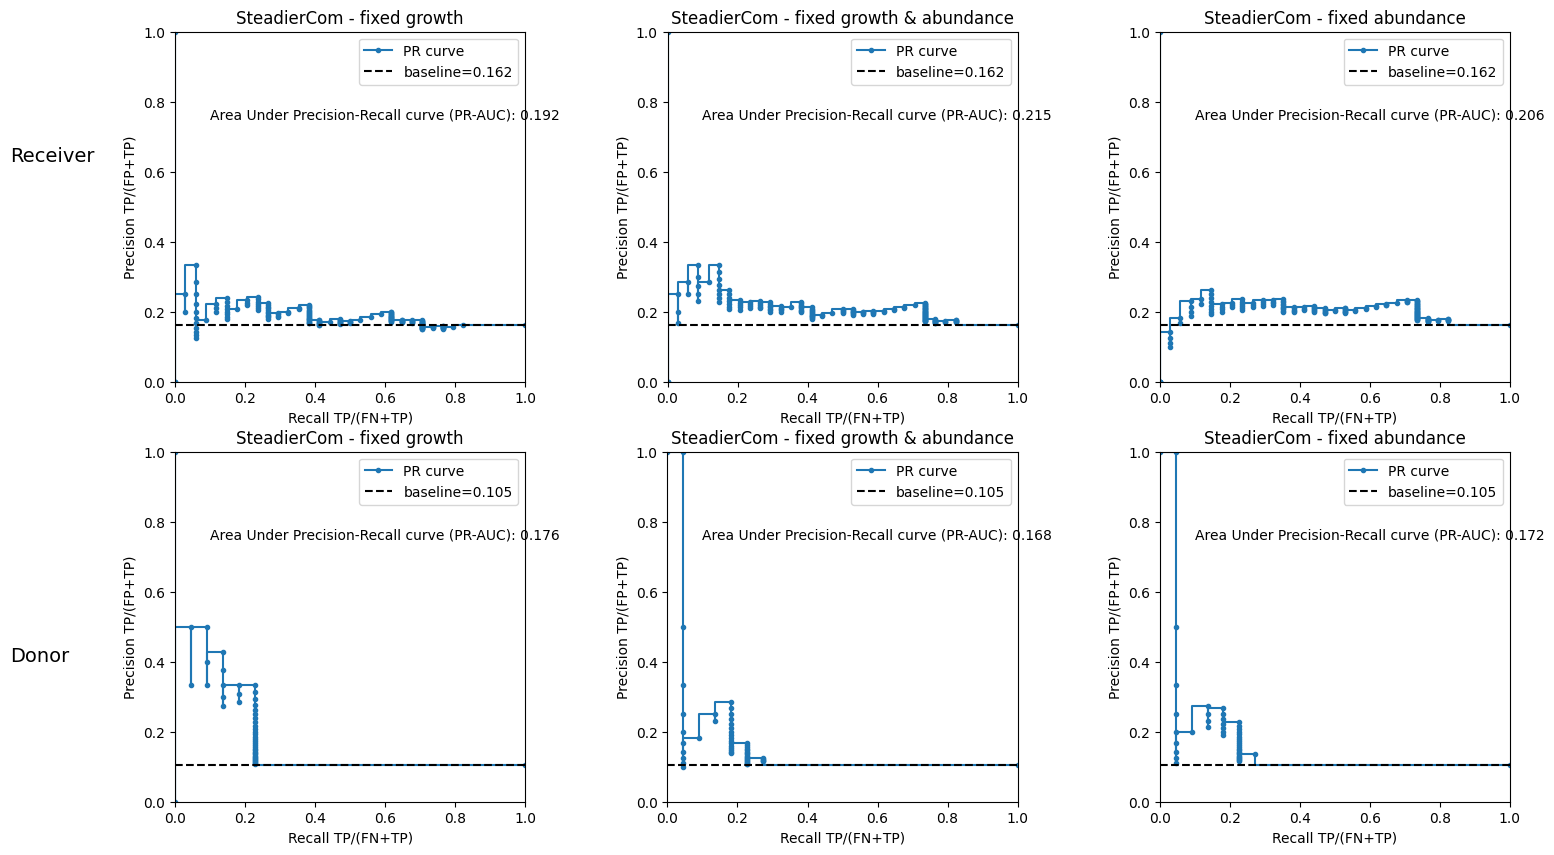

In [27]:
fig,axs =diagnostic.plot_diagnostic_curves(simulation_dict,
                                          signal_exp,
                                          simulation_method="steadiercom",
                                          metric="rate",
                                          met_column="met_group",
                                          agg_method="sum")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_met_exp_sim/diagnostic.py:382: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


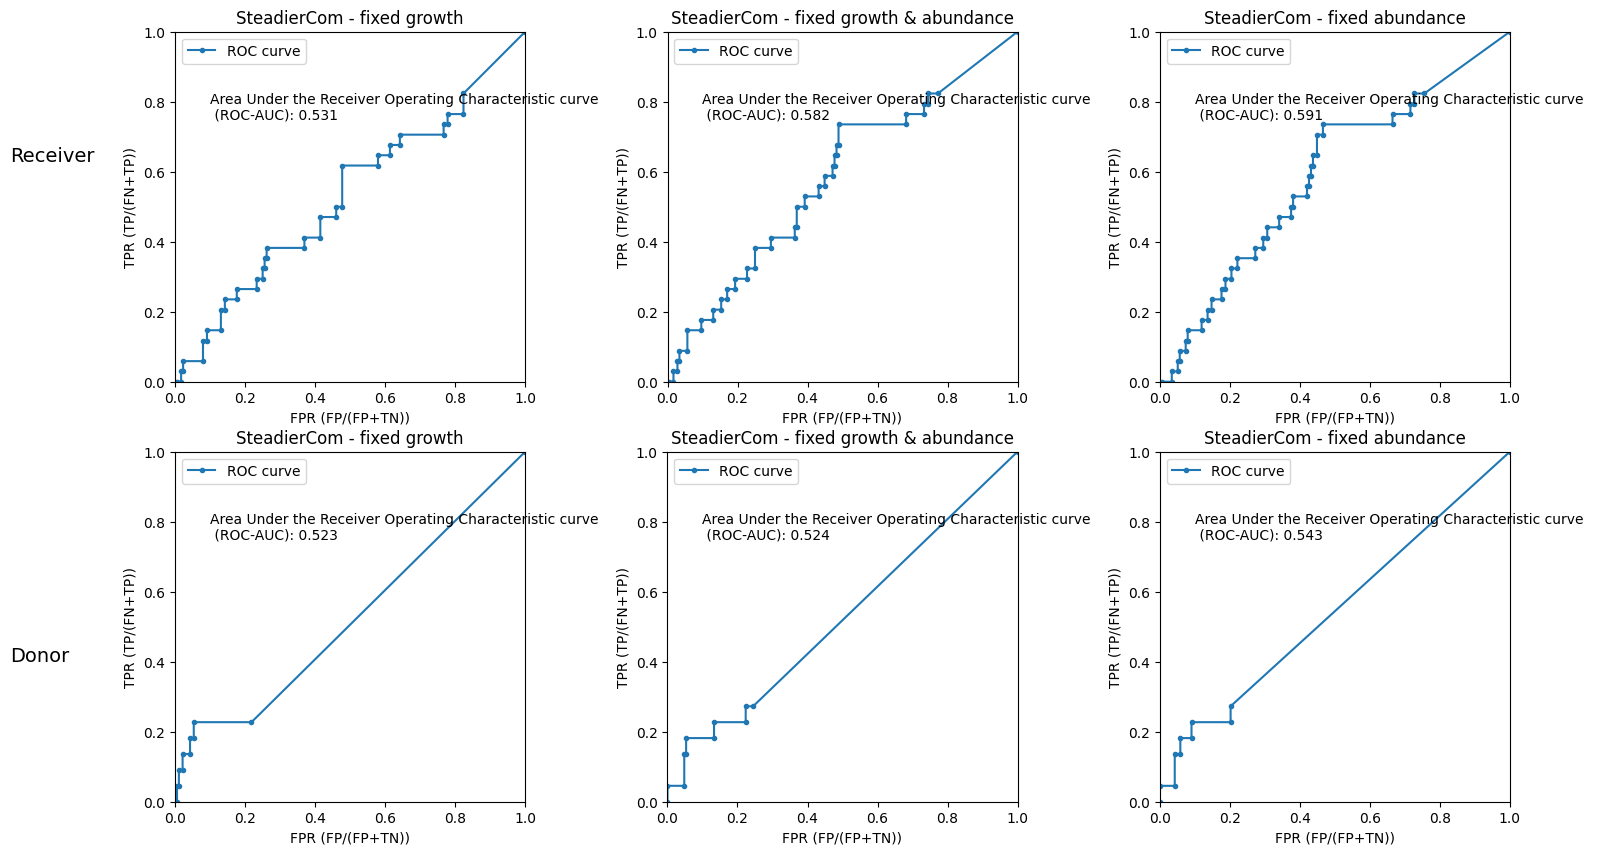

In [28]:
fig,axs =diagnostic.plot_diagnostic_curves(simulation_dict,
                                          signal_exp,
                                          simulation_method="steadiercom",
                                          PR_or_ROC="ROC",
                                          metric="rate",
                                          met_column="met_group",
                                          agg_method="sum")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_met_exp_sim/diagnostic.py:382: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


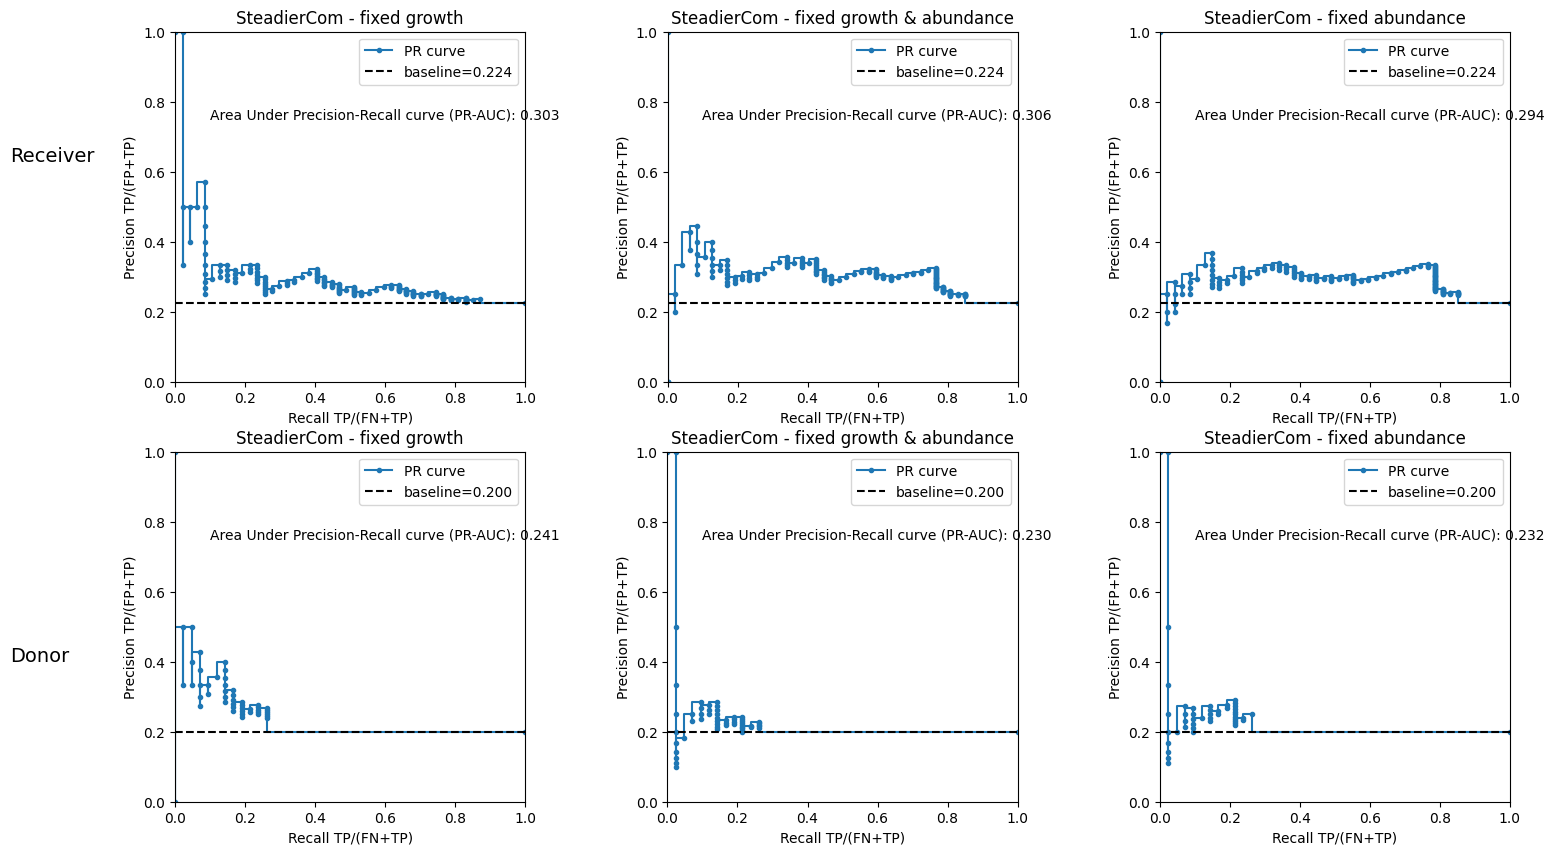

In [29]:
fig,axs =diagnostic.plot_diagnostic_curves(simulation_dict,
                                          signal_exp,
                                          simulation_method="steadiercom",
                                          exp_thresh=0.5,
                                          metric="rate",
                                          met_column="met_group",
                                          agg_method="sum")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_met_exp_sim/diagnostic.py:382: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


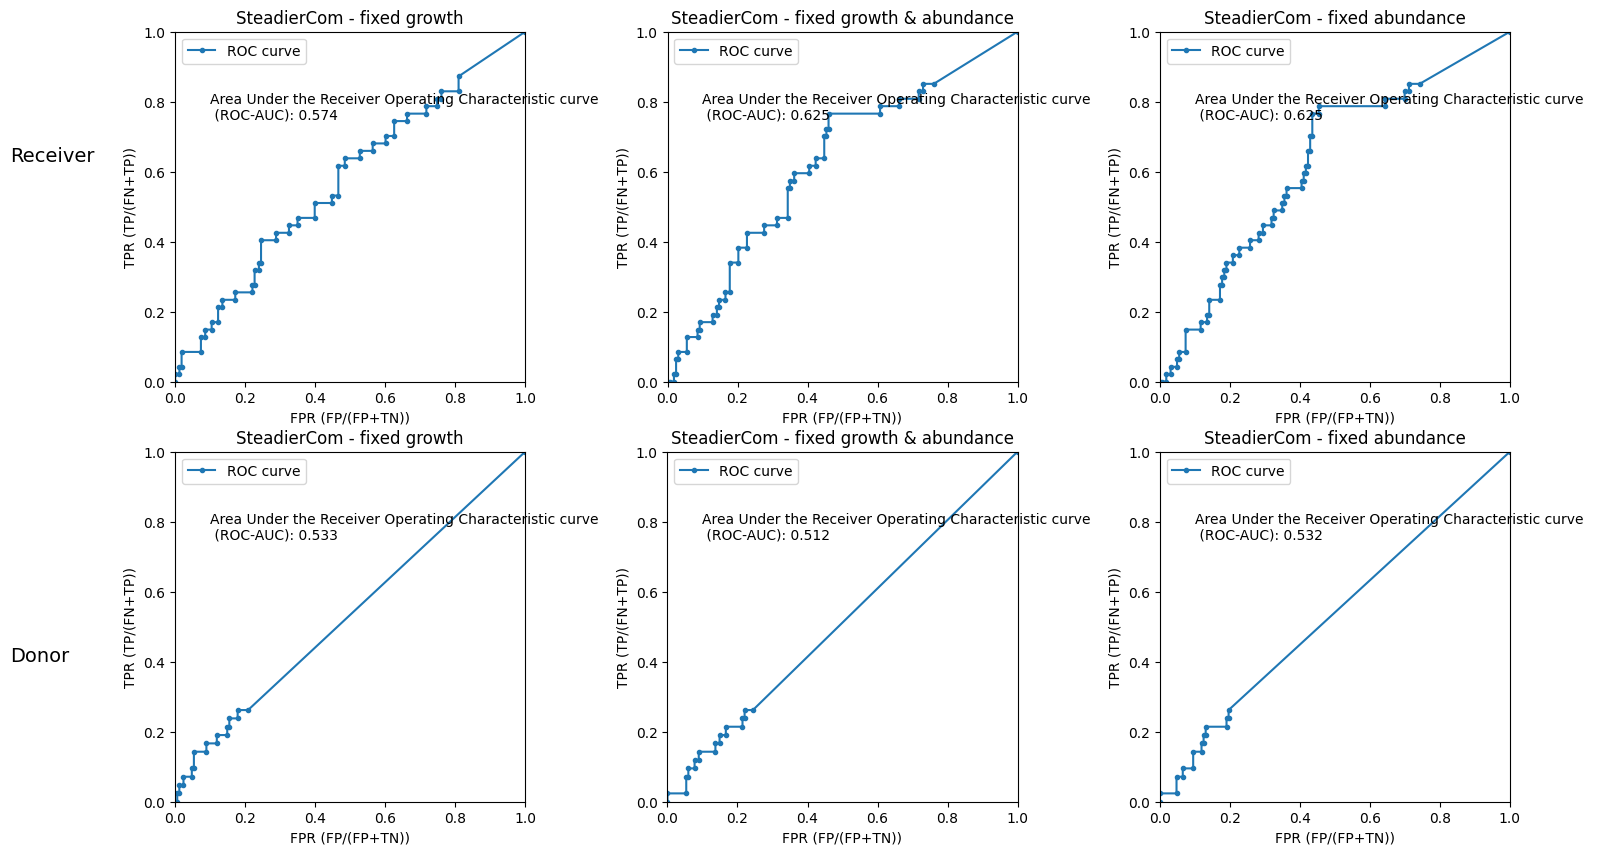

In [30]:
fig,axs =diagnostic.plot_diagnostic_curves(simulation_dict,
                                          signal_exp,
                                          simulation_method="steadiercom",
                                          PR_or_ROC="ROC",
                                          exp_thresh=0.5,
                                          metric="rate",
                                          met_column="met_group",
                                          agg_method="sum")

INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_met_exp_sim/diagnostic.py:382: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


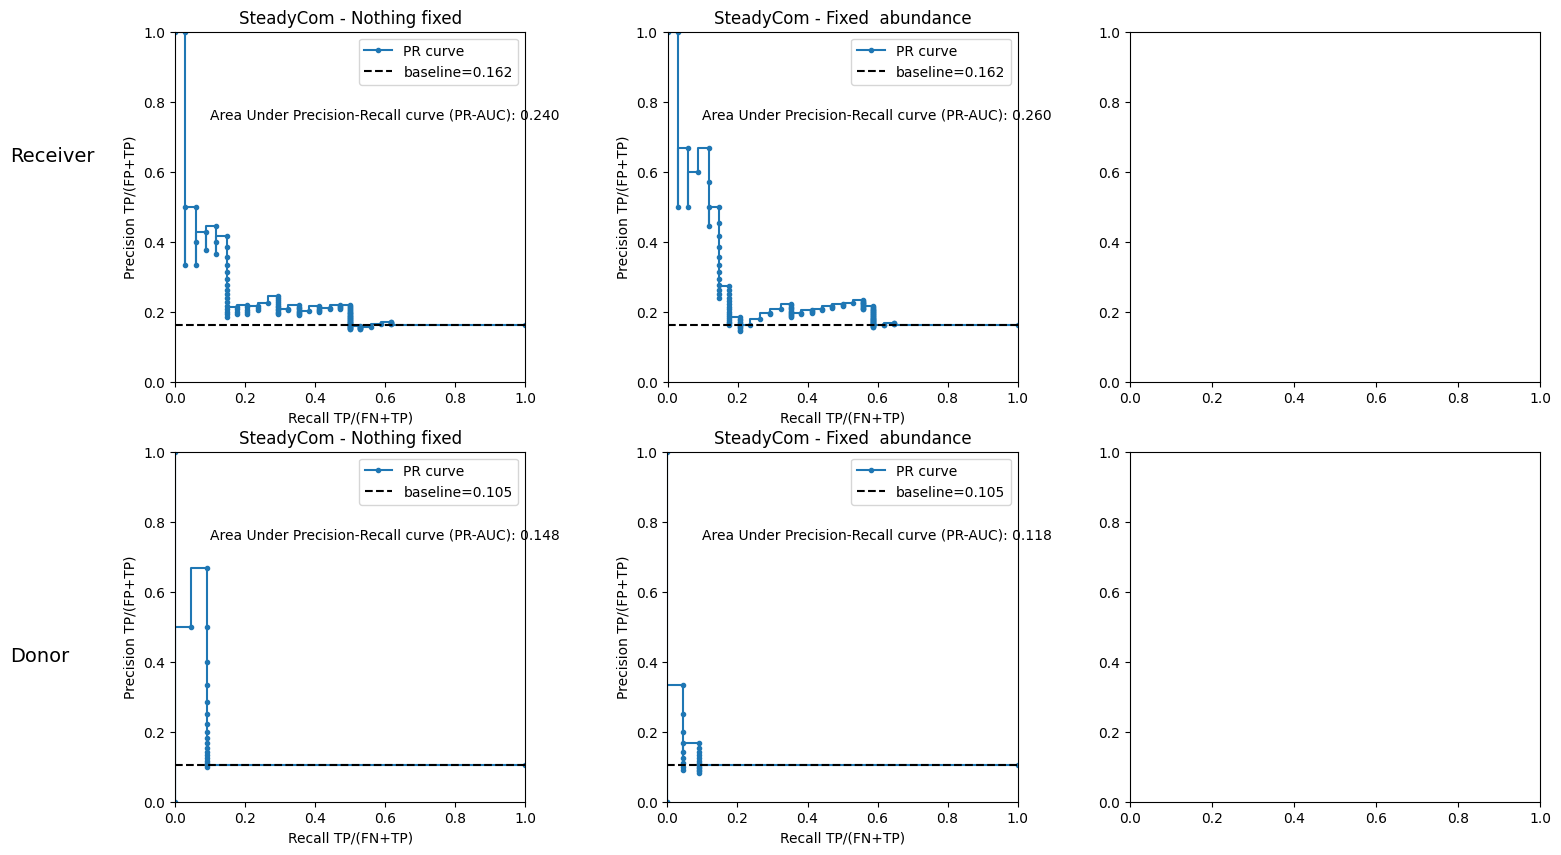

In [31]:
fig,axs = diagnostic.plot_diagnostic_curves(simulation_dict,
                                           signal_exp,
                                           simulation_method="steadycom",
                                           metric="rate?",
                                           met_column="met_group",
                                           agg_method="sum")


INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_met_exp_sim/diagnostic.py:382: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


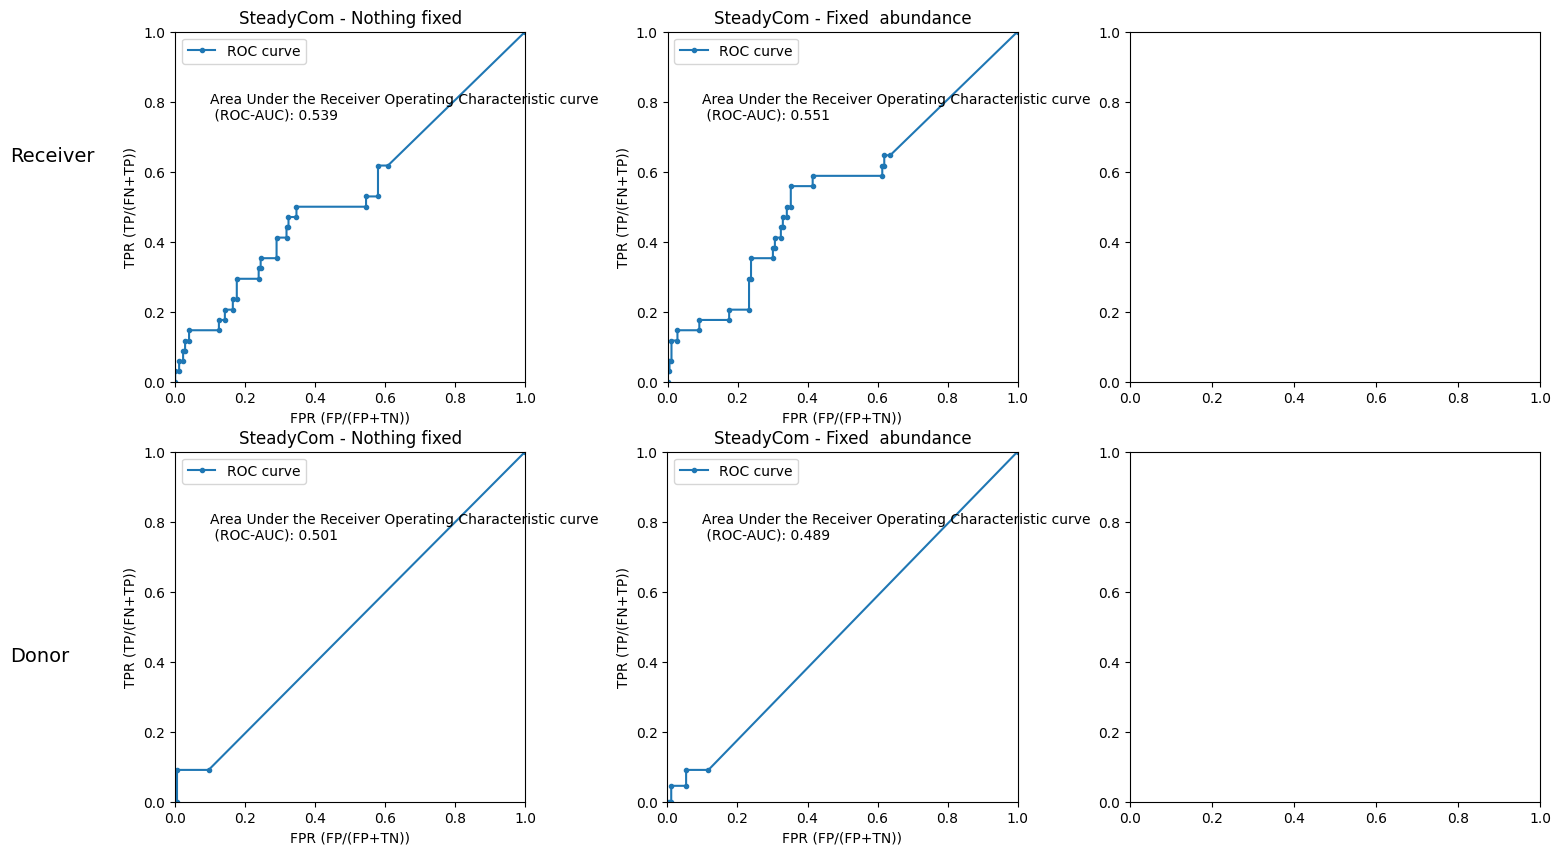

In [32]:
fig,axs = diagnostic.plot_diagnostic_curves(simulation_dict,
                                           signal_exp,
                                           simulation_method="steadycom",
                                           metric="rate?",
                                           PR_or_ROC="ROC",
                                           met_column="met_group",
                                           agg_method="sum")


INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
INFO     | merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_met_exp_sim/diagnostic.py:382: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


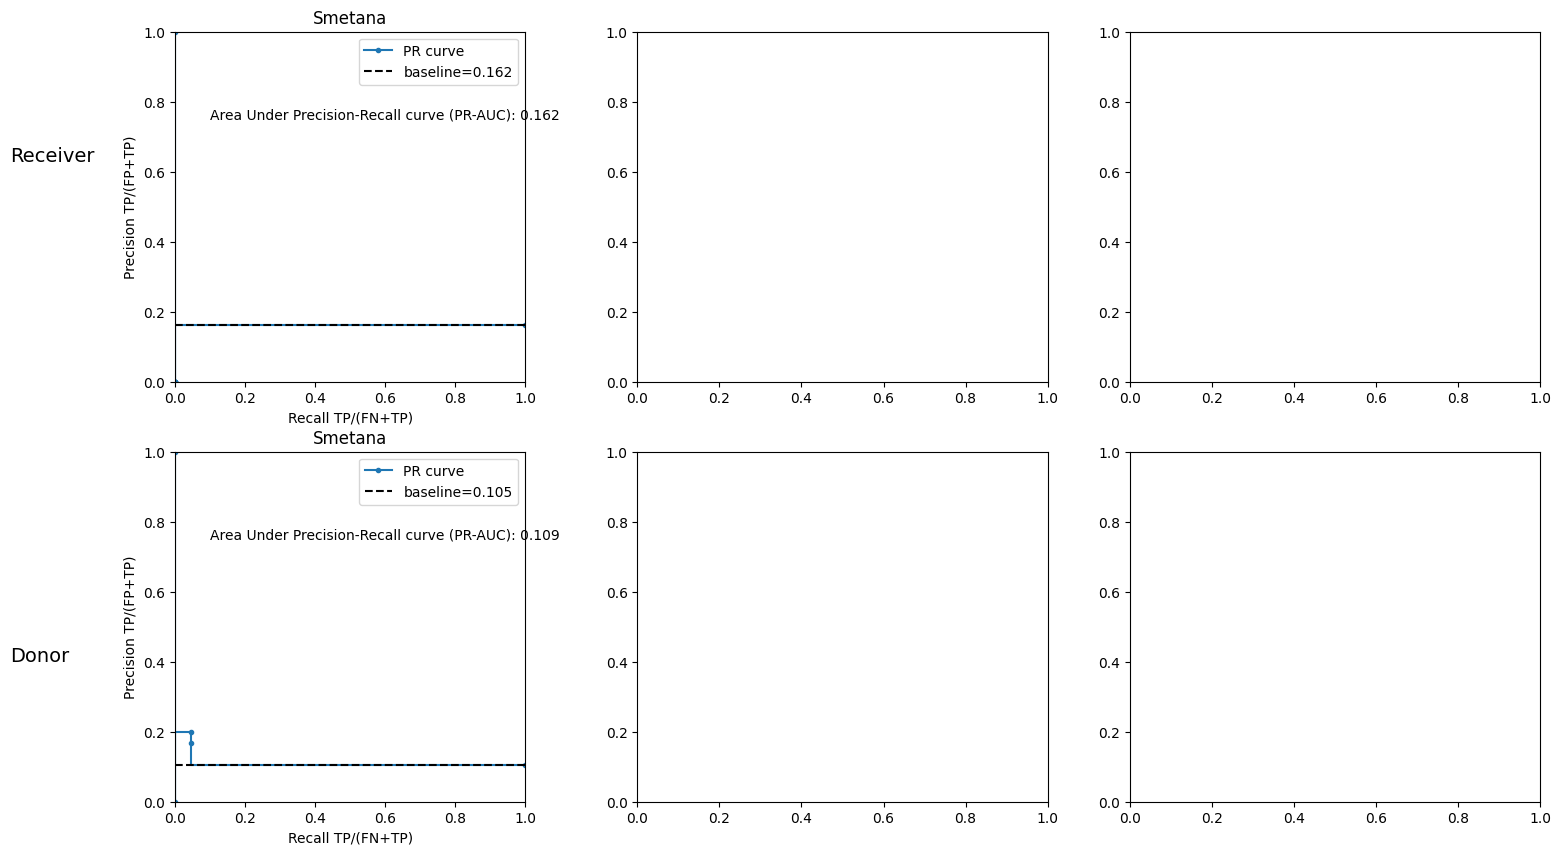

In [33]:
fig,axs = diagnostic.plot_diagnostic_curves(simulation_dict,signal_exp,
                                           simulation_method="smetana",
                                           metric="mus",
                                           met_column="met_group",
                                           agg_method="sum")